# Projet 9 — Mission 2 : Prévoyez l'activité d'un genre musical
## Étapes 4, 5 et 6 — Série temporelle, prévision Prophet, cadence de sortie

**Contexte.** Après la présentation du catalogue au comité éditorial, Camille Roussel demande d'anticiper la place que prendra chaque genre dans les classements, afin que les labels planifient leurs sorties.

**Périmètre de départ** : genre **Pop**, marché **Global**. Le notebook est paramétré pour changer l'un ou l'autre en une ligne.

**Déroulé.**

| Étape | Objet |
|---|---|
| **4** | Construire la série quotidienne du nombre de morceaux du genre dans le Top 200, diagnostiquer les jours vides, dégager la tendance de fond |
| **5** | Entraîner Prophet, l'évaluer honnêtement par backtest sur 90 jours, puis produire la prévision à 6 mois |
| **6** | Refaire l'exercice sur la cadence mensuelle de sorties, et conclure |

---

### Note préalable sur la préparation des données

Le fichier source des classements (`chart_tracks_genre_2017_2020.csv`) pèse ~1,5 Go pour 9 807 001 lignes, à la maille *(date × marché × rang × morceau)*. Il n'est pas chargé ici : un script d'agrégation dédié (`agregation_mission2.py`, lecture par chunks de 1 M de lignes) l'a réduit en amont aux séries de comptage utilisées ci-dessous.

**Ce choix n'est pas qu'une question de volume.** Prophet modélise une série univariée — une date, une valeur. L'objet d'analyse demandé par le brief compte 1 405 points, pas 9,8 millions. L'agrégation *est* la construction de cet objet.

Ce qui est écarté : le rang de chaque morceau, l'identité des titres, les 34 autres marchés. Aucune des questions posées ne les mobilise, et le fichier source reste disponible si le comité pose une question de suivi.

Quatre fichiers agrégés sont produits :

| Fichier | Maille | Rôle |
|---|---|---|
| `serie_global_par_genre.csv` | date × genre | série d'analyse |
| `serie_global_total.csv` | date | référence tous genres confondus, pour le diagnostic des zéros |
| `diagnostic_collecte.csv` | date | volumétrie **tous marchés**, pour distinguer trou de collecte et vrai zéro |
| `sorties_mensuelles_par_genre.csv` | mois × genre | cadence de sortie (étape 6) |


---
# Étape 4 — Construisez et explorez la série temporelle

## 4.1 Paramétrage

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (13, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

# --- PARAMETRES DE L'ANALYSE -------------------------------------------------
GENRE   = "pop"        # genre etudie
MARCHE  = "Global"     # marche etudie
HORIZON = 180          # horizon de prevision, en jours (~6 mois)
TEST_J  = 90           # duree de la periode de test, en jours
# -----------------------------------------------------------------------------

print(f"Genre  : {GENRE}\nMarche : {MARCHE}\nHorizon : {HORIZON} j | Test : {TEST_J} j")

Genre  : pop
Marche : Global
Horizon : 180 j | Test : 90 j


In [2]:
par_genre = pd.read_csv("serie_global_par_genre.csv", parse_dates=["date"])
total     = pd.read_csv("serie_global_total.csv",     parse_dates=["date"])
diag      = pd.read_csv("diagnostic_collecte.csv",    parse_dates=["date"])
sorties   = pd.read_csv("sorties_mensuelles_par_genre.csv", parse_dates=["mois"])

print(f"Serie par genre : {len(par_genre):>6,} lignes | {par_genre.genre.nunique()} genres")
print(f"Serie totale    : {len(total):>6,} lignes")
print(f"Diagnostic      : {len(diag):>6,} dates (tous marches)")
print(f"Sorties         : {len(sorties):>6,} lignes")
par_genre.head(3)

Serie par genre : 19,212 lignes | 18 genres
Serie totale    :  1,401 lignes
Diagnostic      :  1,401 dates (tous marches)
Sorties         :    869 lignes


,country,date,genre,n_morceaux,n_lignes
0,Global,2018-05-15,bolero,1,1
1,Global,2018-05-16,bolero,1,1
2,Global,2018-05-17,bolero,1,1


In [3]:
# Volumetrie par genre : le genre choisi est-il assez represente pour une serie temporelle ?
volumetrie = (par_genre.groupby("genre")
                       .agg(n_jours=("date", "nunique"), moyenne_par_jour=("n_morceaux", "mean"))
                       .sort_values("moyenne_par_jour", ascending=False)
                       .round(1))

if volumetrie.loc[GENRE, "moyenne_par_jour"] < 5:
    print(f"ALERTE : '{GENRE}' compte en moyenne moins de 5 morceaux par jour. "
          f"Serie trop clairsemee pour une prevision fiable.")
volumetrie

,n_jours,moyenne_par_jour
genre,,
pop,1400,81.7
rap,1400,28.3
hip hop,1400,25.1
latin,1400,22.0
dance/electronic,1400,7.9
r&b/soul,1400,6.9
rock,1400,6.4
house,1378,5.3
trap,420,3.1


**Lecture.** 18 genres sont présents. La Pop domine largement (≈ 82 morceaux par jour sur 200), ce qui en fait un bon candidat pour une série temporelle. À l'autre extrémité, `bolero` n'apparaît que 4 jours au total : un contrôle automatique alerte si le genre paramétré est trop clairsemé.

> `else` est une catégorie fourre-tout, pas un genre. Elle est à écarter de toute interprétation métier.

## 4.2 Construction de la série sur une grille de dates complète

**Point de vigilance du brief.** Une série construite par simple `groupby` ignore silencieusement les jours absents du fichier : les points se succèdent alors sans respecter l'axe du temps, et la saisonnalité détectée par le modèle est fausse. On réindexe donc systématiquement sur une grille calendaire continue.

In [4]:
serie_brute = (par_genre.query("genre == @GENRE and country == @MARCHE")
                        .set_index("date")["n_morceaux"]
                        .sort_index())

grille = pd.date_range(total.date.min(), total.date.max(), freq="D")
serie  = serie_brute.reindex(grille)
serie.index.name = "date"

print(f"Periode couverte        : {grille.min():%Y-%m-%d} -> {grille.max():%Y-%m-%d}")
print(f"Jours calendaires       : {len(grille):,}")
print(f"Jours renseignes ('{GENRE}') : {serie_brute.shape[0]:,}")
print(f"Jours ajoutes par la grille  : {len(grille) - serie_brute.shape[0]:,}")

Periode couverte        : 2017-01-01 -> 2020-11-05
Jours calendaires       : 1,405
Jours renseignes ('pop') : 1,400
Jours ajoutes par la grille  : 5


## 4.3 Diagnostic des jours vides — trou de collecte ou vrai zéro ?

La question du brief. Trois sources de preuve sont croisées, du plus large au plus fin :

1. `diagnostic_collecte.csv` — le fichier a-t-il des données ce jour-là, **tous marchés confondus** ?
2. `serie_global_total.csv` — le Top 200 du marché étudié est-il complet ce jour-là, **tous genres confondus** ?
3. la série du genre — le genre est-il réellement absent du classement ?

In [5]:
# Preuve 1 : volumetrie tous marches confondus
print("Lignes par date, tous marches confondus :")
print(diag.n_lignes.describe()[["min", "mean", "max", "std"]].to_string())
print(f"\nMarches distincts par date : min {diag.n_marches.min()}, max {diag.n_marches.max()}")

Lignes par date, tous marches confondus :
min     7000.0
mean    7000.0
max     7000.0
std        0.0

Marches distincts par date : min 35, max 35


**Constat 1.** Chaque date présente dans le fichier affiche **exactement 7 000 lignes réparties sur 35 marchés**, avec un écart-type nul (35 marchés × 200 rangs). La collecte est parfaitement homogène : il n'existe aucune date partiellement renseignée. Une date est soit complète pour les 35 marchés, soit totalement absente.

In [6]:
# Preuve 2 : dates entierement absentes du fichier
dates_absentes = grille.difference(total.date)
print(f"Dates absentes du fichier : {len(dates_absentes)}")
for d in dates_absentes:
    print(f"   {d:%Y-%m-%d}  ({d:%A})")

Dates absentes du fichier : 4
   2017-02-23  (Thursday)
   2017-05-30  (Tuesday)
   2017-05-31  (Wednesday)
   2017-06-02  (Friday)


In [7]:
# Preuve 3 : dates presentes mais incoherentes
# Le Top 200 doit contenir 200 morceaux DISTINCTS. Un fort ecart entre le nombre
# de lignes et le nombre de morceaux distincts revele une anomalie de collecte.
tot = total.query("country == @MARCHE").set_index("date")
tot["ratio"] = tot.n_morceaux_total / tot.n_lignes_total

anomalies = tot[tot.ratio < 0.9]
print(f"Dates presentes mais incoherentes : {len(anomalies)}")
anomalies

Dates presentes mais incoherentes : 1


,country,n_morceaux_total,n_lignes_total,ratio
date,,,,
2018-06-09,Global,1,200,0.005


**Constat 3 — une date corrompue.** Le **2018-06-09** comporte bien 200 lignes, mais **un seul morceau distinct** : le même `uri` répété 200 fois, avec un genre non renseigné. Le classement de ce jour-là n'a pas été collecté correctement.

Cette date est particulièrement traître : elle est **absente de la série par genre** (le regroupement élimine les genres nuls) sans être absente du fichier. Sans ce contrôle croisé, elle serait passée pour un jour ordinaire.

In [8]:
# Synthese : reconstitution du statut de chaque jour de la grille
dates_corrompues = anomalies.index

statut = pd.Series("renseigne", index=grille, name="statut")
statut[statut.index.isin(dates_absentes)]   = "absent du fichier"
statut[statut.index.isin(dates_corrompues)] = "collecte corrompue"
statut[serie.isna() & (statut == "renseigne")] = "genre absent du Top 200"

recap = statut.value_counts().to_frame("n_jours")
recap["part_%"] = (recap.n_jours / len(grille) * 100).round(2)
print(f"Vrais zeros dans la serie '{GENRE}' : {(serie == 0).sum()}")
recap

Vrais zeros dans la serie 'pop' : 0


,n_jours,part_%
statut,,
renseigne,1400,99.64
absent du fichier,4,0.28
collecte corrompue,1,0.07


### Conclusion du diagnostic

| Statut | Jours | Interprétation |
|---|---|---|
| Renseigné | 1 400 | Série exploitable |
| Absent du fichier | 4 | 2017-02-23, 2017-05-30, 2017-05-31, 2017-06-02 — **trous de collecte**, confirmés par l'absence simultanée des 35 marchés |
| Collecte corrompue | 1 | 2018-06-09 — 200 lignes mais 1 seul morceau distinct |
| Genre absent du Top 200 | 0 | — |

**Aucun vrai zéro.** Le minimum de la série Pop est de 51 morceaux : le genre n'a jamais disparu du Top 200 Global sur toute la période.

**→ Décision : les 5 discontinuités sont laissées en `NaN`, jamais mises à 0.**

Justification. Un 0 affirmerait que la Pop était absente du classement ce jour-là — une information fausse, que le modèle interpréterait comme un effondrement réel et intégrerait à la saisonnalité. `NaN` dit « on ne sait pas », ce qui est la vérité.

**Faut-il imputer ces 5 jours ?** Non. Prophet accepte nativement les trous : il ajuste sa courbe sur les dates renseignées et ne réclame pas de série continue. Imputer reviendrait à fabriquer 5 observations et à leur donner le même poids qu'à des mesures réelles. La grille continue reste néanmoins indispensable — elle garantit que l'axe temporel est correct et rend les trous visibles au lieu de les masquer.

## 4.4 Visualisation de la série et de sa tendance de fond

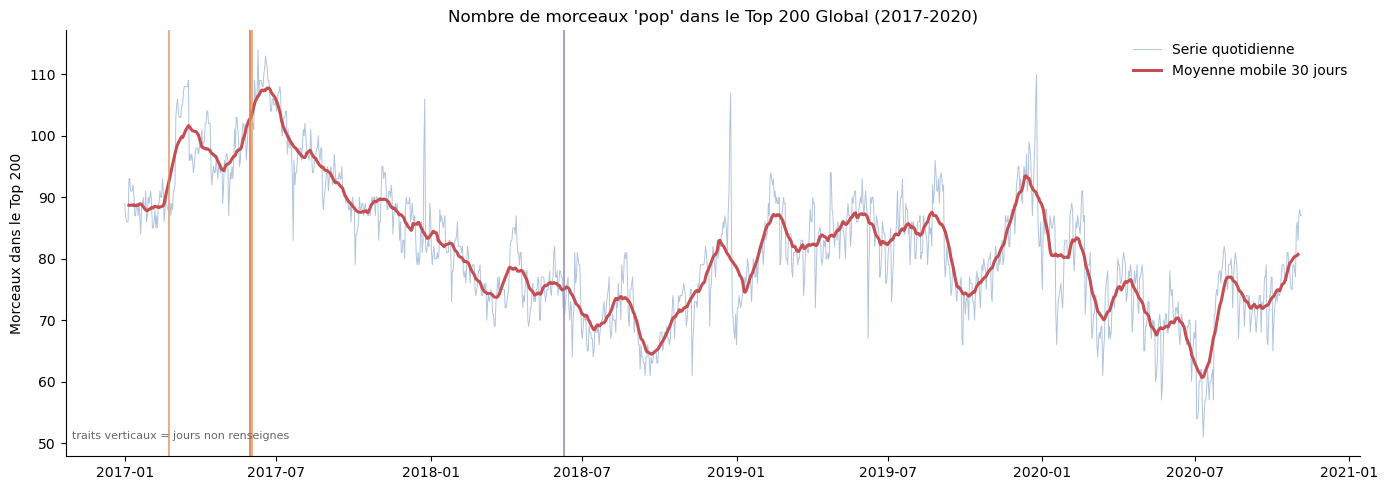

In [9]:
moy_mobile = serie.rolling(window=30, center=True, min_periods=20).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(serie.index, serie.values, lw=0.7, color="#B0C4DE", label="Serie quotidienne")
ax.plot(moy_mobile.index, moy_mobile.values, lw=2.2, color="#C44E52",
        label="Moyenne mobile 30 jours")

for d in dates_absentes:
    ax.axvline(d, color="#DD8452", lw=1.2, alpha=0.8)
for d in dates_corrompues:
    ax.axvline(d, color="#8172B3", lw=1.2, alpha=0.8)

ax.set_title(f"Nombre de morceaux '{GENRE}' dans le Top 200 {MARCHE} (2017-2020)")
ax.set_ylabel("Morceaux dans le Top 200")
ax.set_xlabel("")
ax.legend(loc="upper right", frameon=False)
ax.text(0.005, 0.04, "traits verticaux = jours non renseignes",
        transform=ax.transAxes, fontsize=8, color="#666")
plt.tight_layout()
plt.show()

In [10]:
stats = serie.describe()[["mean", "std", "min", "50%", "max"]].round(1)
annuel = serie.groupby(serie.index.year).agg(["mean", "min", "max"]).round(1)
print("Statistiques globales :"); print(stats.to_string())
print("\nPar annee :"); print(annuel.to_string())

Statistiques globales :
mean     81.7
std      10.7
min      51.0
50%      81.0
max     114.0

Par annee :
      mean   min    max
date                   
2017  94.1  79.0  114.0
2018  74.8  61.0  107.0
2019  83.3  66.0  110.0
2020  73.7  51.0   91.0


**Lecture du graphique — ce qu'on dit au comité.**

- **Une tendance de fond baissière, mais non linéaire.** La Pop passe de ~94 morceaux/jour en 2017 à ~74 en 2018, remonte à ~83 en 2019, puis redescend à ~74 en 2020. Ce **rebond de 2019 casse la ligne droite** : une simple régression linéaire serait trompeuse. C'est précisément ce qui justifie un modèle à tendance flexible.
- **Une amplitude élevée** : la série oscille entre 51 et 114 morceaux, soit du simple au double. Le bruit quotidien est important par rapport à la tendance.
- **Une lecture métier** : le Top 200 est un jeu à somme constante. Reculer de 94 à 74 morceaux ne signifie pas que la Pop produit moins, mais qu'elle **cède du terrain** — vraisemblablement au rap, au latin et au hip hop, dont la part progresse sur la même période.

## 4.5 Motifs récurrents — saisonnalités hebdomadaire et annuelle

/var/folders/t7/klgz_38n3yxgnnl73v7f3_gm0000gn/T/ipykernel_4600/1470552903.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([df_s.loc[df_s.jour_sem == j, "n"] for j in range(7)], labels=jours,
/var/folders/t7/klgz_38n3yxgnnl73v7f3_gm0000gn/T/ipykernel_4600/1470552903.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([df_s.loc[df_s.mois == m, "n"] for m in range(1, 13)], labels=mois_lbl,


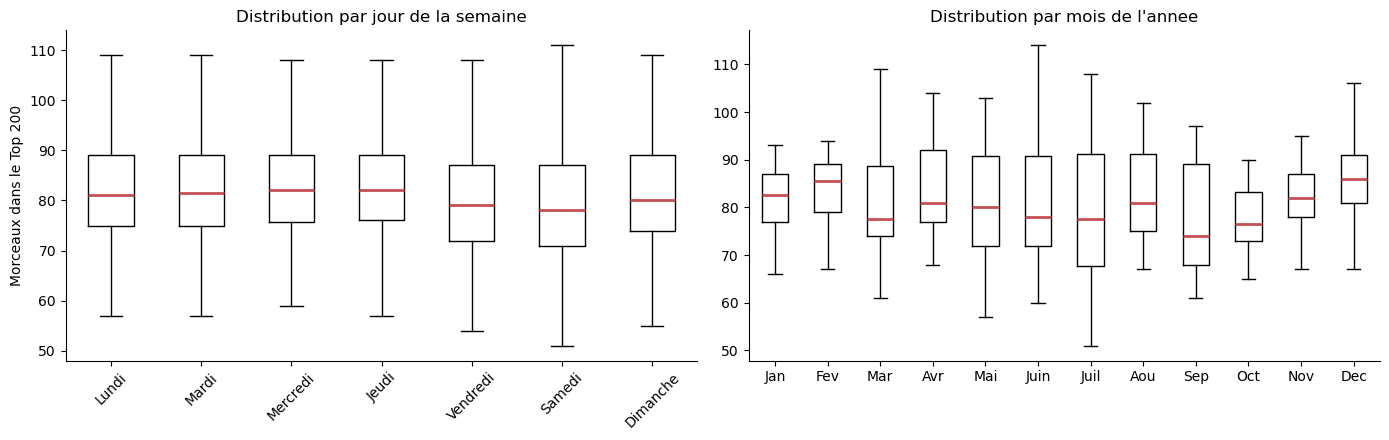

Moyenne par jour de la semaine :
Lundi       82.88
Mardi       82.74
Mercredi    82.95
Jeudi       82.72
Vendredi    79.95
Samedi      79.64
Dimanche    81.29

Ecart max entre jours : 3.3 morceaux (4.0 % de la moyenne)


In [11]:
jours = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
mois_lbl = ["Jan", "Fev", "Mar", "Avr", "Mai", "Juin", "Juil", "Aou", "Sep", "Oct", "Nov", "Dec"]

df_s = serie.to_frame("n").dropna()
df_s["jour_sem"] = df_s.index.dayofweek
df_s["mois"] = df_s.index.month

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].boxplot([df_s.loc[df_s.jour_sem == j, "n"] for j in range(7)], labels=jours,
                showfliers=False, medianprops=dict(color="#C44E52", lw=2))
axes[0].set_title("Distribution par jour de la semaine")
axes[0].set_ylabel("Morceaux dans le Top 200")
axes[0].tick_params(axis="x", rotation=45)

axes[1].boxplot([df_s.loc[df_s.mois == m, "n"] for m in range(1, 13)], labels=mois_lbl,
                showfliers=False, medianprops=dict(color="#C44E52", lw=2))
axes[1].set_title("Distribution par mois de l'annee")

plt.tight_layout()
plt.show()

profil = df_s.groupby("jour_sem")["n"].mean().round(2)
profil.index = jours
print("Moyenne par jour de la semaine :"); print(profil.to_string())
print(f"\nEcart max entre jours : {profil.max() - profil.min():.1f} morceaux "
      f"({(profil.max() - profil.min()) / profil.mean() * 100:.1f} % de la moyenne)")

**Motif hebdomadaire — un résultat contre-intuitif à défendre.**

Le creux hebdomadaire tombe le **vendredi et le samedi** (≈ 79,6-79,9 morceaux), contre ≈ 82,9 en milieu de semaine. On attendrait l'inverse : le vendredi est le jour traditionnel de sortie des nouveautés, donc un jour de forte activité.

**L'explication tient à la nature du Top 200 : un classement à taille fixe.** Le vendredi, les nouveautés affluent **tous genres confondus**. Chaque entrée d'un titre rap, latin ou hip hop expulse mécaniquement un titre d'un autre genre. La Pop, qui occupe 40 % du classement, est la première à céder des places par simple effet de masse.

Autrement dit : **le pic de sorties du vendredi existe bien, mais il se lit comme un creux pour un genre dominant.** L'amplitude reste modeste (3,3 morceaux, soit 4 % de la moyenne) — la saisonnalité hebdomadaire est réelle mais secondaire face à la tendance.

**Motif annuel.** Les écarts mensuels sont plus marqués, avec un creux estival. À interpréter avec prudence : sur seulement 4 années d'historique, un motif mensuel peut refléter des événements ponctuels (une sortie majeure) autant qu'une vraie saisonnalité.

---
# Étape 5 — Entraînez, évaluez et prévoyez avec Prophet

## 5.1 Découpage entraînement / validation / test

**Point de vigilance éliminatoire du brief.** Évaluer un modèle sur des données qu'il a vues à l'entraînement ne mesure rien. La période de test doit être **strictement postérieure** à la période d'entraînement — et il ne peut pas s'agir d'un tirage aléatoire : sur une série temporelle, mélanger les dates reviendrait à laisser le modèle lire l'avenir.

**Un second piège, plus discret.** Ce notebook compare plusieurs configurations de Prophet pour choisir la meilleure. Si ce choix se fait au vu des résultats sur le test, le test cesse d'être un test : on aurait sélectionné le modèle qui colle le mieux à des données censées être inconnues, et la performance annoncée serait surévaluée. **Un jeu de données ne peut pas servir à la fois à choisir et à juger.**

D'où un découpage en trois blocs, chronologiques et disjoints :

| Bloc | Période | Rôle |
|---|---|---|
| **Entraînement** | du début à 2020-05-09 | ajuster les paramètres du modèle |
| **Validation** | 90 jours | **choisir** la configuration |
| **Test** | 90 derniers jours | **juger** la configuration retenue, une seule fois |

In [12]:
VALID_J = 90   # duree de la periode de validation, en jours

fin_serie    = serie.index.max()
debut_test   = fin_serie - pd.Timedelta(days=TEST_J - 1)
debut_valid  = debut_test - pd.Timedelta(days=VALID_J)

train = serie[serie.index <  debut_valid]
valid = serie[(serie.index >= debut_valid) & (serie.index < debut_test)]
test  = serie[serie.index >= debut_test]

# Bloc d'entrainement du modele final : entrainement + validation reunis,
# utilise une fois la configuration choisie.
train_complet = serie[serie.index < debut_test]

for nom, bloc in [("Entrainement", train), ("Validation", valid), ("Test", test)]:
    print(f"{nom:<13} {bloc.index.min():%Y-%m-%d} -> {bloc.index.max():%Y-%m-%d}  "
          f"({len(bloc):>4,} jours, {bloc.notna().sum():>4,} renseignes)")

recouvrements = (len(set(train.index) & set(valid.index))
                 + len(set(valid.index) & set(test.index))
                 + len(set(train.index) & set(test.index)))
print(f"\nRecouvrement entre blocs : {recouvrements} jour(s)")
print(f"Couverture totale        : {len(train)+len(valid)+len(test):,} / {len(serie):,} jours")

Entrainement  2017-01-01 -> 2020-05-09  (1,225 jours, 1,220 renseignes)
Validation    2020-05-10 -> 2020-08-07  (  90 jours,   90 renseignes)
Test          2020-08-08 -> 2020-11-05  (  90 jours,   90 renseignes)

Recouvrement entre blocs : 0 jour(s)
Couverture totale        : 1,405 / 1,405 jours


In [13]:
def au_format_prophet(s):
    """Convertit une serie indexee par date au format attendu par Prophet (ds, y).
    Les NaN sont conserves : Prophet ignore ces lignes a l'entrainement."""
    d = s.reset_index()
    d.columns = ["ds", "y"]
    return d

df_train         = au_format_prophet(train)
df_train_complet = au_format_prophet(train_complet)

print(df_train.tail(3).to_string(index=False))
print(f"\nObservations d'entrainement (hors NaN) : {df_train.y.notna().sum():,}")

        ds    y
2020-05-07 73.0
2020-05-08 70.0
2020-05-09 69.0

Observations d'entrainement (hors NaN) : 1,220


## 5.2 Métriques d'évaluation

Trois métriques sont demandées. Elles ne disent pas la même chose et se lisent ensemble.

| Métrique | Ce qu'elle mesure | Unité |
|---|---|---|
| **MAE** | erreur typique, toutes traitées à poids égal | morceaux |
| **RMSE** | erreur typique, **pénalisant les grosses erreurs** | morceaux |
| **MAPE** | erreur relative, comparable entre séries | % |
| **Biais** | erreur moyenne **signée** | morceaux |

RMSE > MAE signale quelques erreurs nettement plus grandes que les autres. Et le **biais** est la métrique la plus révélatrice des trois : si sa valeur absolue approche la MAE, le modèle se trompe **toujours dans le même sens** — l'erreur n'est plus du bruit, c'est un défaut structurel.

In [14]:
def evaluer(reel, prevu, nom="Modele"):
    """MAE, RMSE, MAPE et biais, calcules sur les seules dates renseignees."""
    reel, prevu = np.asarray(reel, float), np.asarray(prevu, float)
    ok = ~np.isnan(reel) & ~np.isnan(prevu)
    reel, prevu = reel[ok], prevu[ok]
    err = reel - prevu
    return {"modele": nom, "n": len(reel),
            "MAE": np.abs(err).mean(),
            "RMSE": np.sqrt((err ** 2).mean()),
            "MAPE_%": np.abs(err / reel).mean() * 100,
            "biais": err.mean()}

print(f"Minimum de la periode de test : {test.min():.0f} morceaux")
print("=> Aucune valeur proche de zero : la MAPE est ici stable et interpretable.")

Minimum de la periode de test : 65 morceaux
=> Aucune valeur proche de zero : la MAPE est ici stable et interpretable.


> **Vérification demandée par le brief.** La MAPE explose quand les valeurs réelles approchent de zéro. Ici le minimum de la période de test est largement supérieur à zéro : la métrique est fiable.

## 5.3 Modèle de référence — le seuil que Prophet doit battre

Une métrique seule ne dit pas si un modèle est bon : 5 morceaux d'erreur, est-ce beaucoup ? On construit donc un **modèle naïf** — reproduire la dernière semaine observée à l'identique sur tout l'horizon. Il capte le niveau récent et le motif hebdomadaire, sans rien apprendre.

**Si Prophet ne le bat pas, sa complexité n'est pas justifiée.** Ce n'est pas une formalité : c'est le premier réflexe attendu en évaluation de modèle.

In [15]:
def naif_saisonnier(historique, n_periodes, saison=7):
    """Reconduit les `saison` dernieres valeurs observees sur `n_periodes`."""
    derniere = historique.dropna().iloc[-saison:].values
    return np.tile(derniere, int(np.ceil(n_periodes / saison)))[:n_periodes]

naif_valid = naif_saisonnier(train, len(valid))
naif_test  = naif_saisonnier(train_complet, len(test))

res_naif_valid = evaluer(valid.values, naif_valid, "Naif saisonnier (7 j)")
res_naif_test  = evaluer(test.values,  naif_test,  "Naif saisonnier (7 j)")

pd.DataFrame([{**res_naif_valid, "bloc": "validation"},
              {**res_naif_test,  "bloc": "test"}]).set_index(["bloc", "modele"]).round(2)

,,n,MAE,RMSE,MAPE_%,biais
bloc,modele,,,,,
validation,Naif saisonnier (7 j),90,5.86,7.49,9.29,-3.01
test,Naif saisonnier (7 j),90,4.92,5.78,6.68,-3.77


## 5.4 Modèle par défaut — et pourquoi il échoue

On commence par la configuration la plus naturelle : saisonnalités annuelle et hebdomadaire activées, saisonnalité quotidienne désactivée (la série est déjà quotidienne, il n'existe aucun cycle intra-journalier à modéliser). Tous les autres paramètres restent à leur valeur par défaut.

**Ce modèle sert de point de départ au diagnostic, pas de livrable.**

In [16]:
from prophet import Prophet
import logging, itertools, warnings
logging.getLogger("prophet").setLevel(logging.ERROR)
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

def ajuster_prophet(df_entrainement, index_cible, **params):
    """Entraine un Prophet et renvoie ses previsions sur les dates de `index_cible`."""
    base = dict(yearly_seasonality=True, weekly_seasonality=True,
                daily_seasonality=False, seasonality_mode="additive",
                interval_width=0.95)
    base.update(params)
    m = Prophet(**base)
    m.fit(df_entrainement)
    horizon = (index_cible.max() - pd.Timestamp(df_entrainement.ds.max())).days
    futur = m.make_future_dataframe(periods=horizon, freq="D")
    prev = m.predict(futur)
    return m, prev, prev.set_index("ds").reindex(index_cible)

modele_def, prev_def, pred_def = ajuster_prophet(df_train_complet, test.index)
res_def = evaluer(test.values, pred_def.yhat.values, "Prophet (defaut)")

comparaison = pd.DataFrame([res_naif_test, res_def]).set_index("modele").round(2)
comparaison

14:17:00 - cmdstanpy - INFO - Chain [1] start processing
14:17:00 - cmdstanpy - INFO - Chain [1] done processing


,n,MAE,RMSE,MAPE_%,biais
modele,,,,,
Naif saisonnier (7 j),90,4.92,5.78,6.68,-3.77
Prophet (defaut),90,18.24,19.49,23.94,18.24


In [17]:
couverture_def = ((test.values >= pred_def.yhat_lower.values) &
                  (test.values <= pred_def.yhat_upper.values))
print(f"Points reels dans l'intervalle a 95 % : {np.nanmean(couverture_def)*100:.1f} %")
print(f"Ratio |biais| / MAE                   : {abs(res_def['biais'])/res_def['MAE']:.2f}")
print("   (proche de 1 => erreur systematique, toujours dans le meme sens)")

Points reels dans l'intervalle a 95 % : 6.7 %
Ratio |biais| / MAE                   : 1.00
   (proche de 1 => erreur systematique, toujours dans le meme sens)


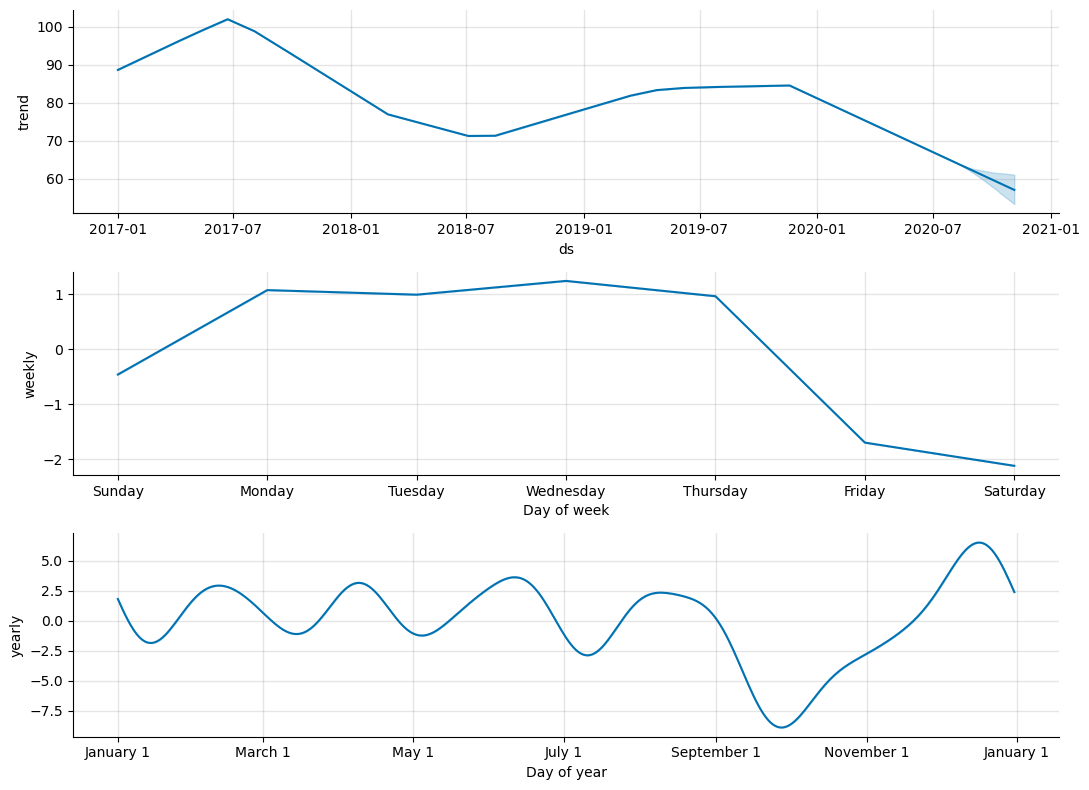

Amplitude 'trend' : 44.9 morceaux
Amplitude 'weekly' : 3.4 morceaux
Amplitude 'yearly' : 15.4 morceaux


In [18]:
fig = modele_def.plot_components(prev_def)
fig.set_size_inches(11, 8)
plt.tight_layout()
plt.show()

# Amplitude de chaque composante : laquelle domine la prevision ?
for comp in ["trend", "weekly", "yearly"]:
    if comp in prev_def.columns:
        amp = prev_def[comp].max() - prev_def[comp].min()
        print(f"Amplitude '{comp}' : {amp:.1f} morceaux")

**Diagnostic.** Trois symptômes se lisent ensemble et pointent la même cause.

1. **Le ratio |biais| / MAE approche 1.** Le modèle ne se trompe pas au hasard : il dévie toujours dans le même sens. C'est un défaut de construction, pas du bruit.
2. **La couverture de l'intervalle à 95 % s'effondre.** Les intervalles sont correctement dimensionnés pour du bruit aléatoire, mais ne peuvent rien contre un décalage systématique.
3. **L'amplitude de la composante annuelle est disproportionnée** face à la composante hebdomadaire.

**La cause : une saisonnalité annuelle surajustée.** Prophet estime le motif annuel par une série de Fourier d'ordre 10 par défaut, soit 20 paramètres, à partir de **moins de 4 cycles annuels**. Avec si peu de répétitions, il ne peut pas distinguer un vrai motif saisonnier d'accidents ponctuels : les creux d'été de 2018 et 2020 sont absorbés dans le « motif annuel » et rejoués mécaniquement sur la période de test.

**Cause aggravante : une tendance figée.** Le paramètre `changepoint_range` vaut 0,8 par défaut — aucun point de rupture n'est autorisé sur les 20 % finaux de l'historique. La dynamique la plus récente, celle qui compte le plus pour prévoir, n'influence donc pas la pente terminale.

**→ Ces deux paramètres sont précisément ceux que la section suivante fait varier.**

## 5.5 Sélection par validation croisée à origine glissante

### Pourquoi une seule fenêtre de validation ne suffit pas

Une première approche consisterait à réserver 90 jours de validation, y comparer toutes les configurations et retenir la meilleure. **Cette méthode échoue sur cette série**, pour une raison qui mérite d'être comprise.

Quand on compare des dizaines de configurations sur une **unique** fenêtre, l'écart entre la meilleure et le modèle naïf se réduit souvent à quelques pourcents. À ce niveau, on ne mesure plus une différence de qualité : on mesure le hasard de cette fenêtre-là. La configuration retenue est celle qui a **eu de la chance**, pas celle qui généralise — c'est la *malédiction du vainqueur*. Elle s'effondre dès qu'on la teste ailleurs.

### Le correctif : évaluer chaque configuration sur plusieurs origines

Chaque configuration est entraînée puis évaluée à **plusieurs dates de coupure successives**, toutes situées avant le test. On obtient ainsi une distribution d'erreurs par configuration, et non un chiffre unique.

Trois indicateurs en découlent, et ils comptent autant l'un que l'autre :

| Indicateur | Ce qu'il révèle |
|---|---|
| **MAE moyenne** | performance d'ensemble |
| **Écart-type de la MAE** | **stabilité** — une configuration excellente une fois sur deux et catastrophique l'autre est inutilisable |
| **Taux de victoire sur le naïf** | robustesse : gagner sur 7 coupures sur 8 vaut mieux qu'un gain moyen porté par une seule |

Le modèle naïf est réévalué **à chaque coupure**, sur exactement les mêmes fenêtres. On saura ainsi si sa supériorité est constante ou circonstancielle.

In [19]:
# Construction des origines de coupure : toutes situees avant le debut du test,
# chacune suivie d'une fenetre d'evaluation de TEST_J jours entierement connue.
PAS_COUPURE = 60      # jours entre deux origines successives
MIN_TRAIN   = 730     # historique minimal exige pour entrainer (2 ans)

coupures = []
c = debut_test - pd.Timedelta(days=TEST_J)
while (c - serie.index.min()).days >= MIN_TRAIN:
    coupures.append(c)
    c -= pd.Timedelta(days=PAS_COUPURE)
coupures = sorted(coupures)

print(f"Origines de coupure : {len(coupures)}")
for c in coupures:
    fin = c + pd.Timedelta(days=TEST_J - 1)
    print(f"   entrainement -> {c:%Y-%m-%d}  |  evaluation {c:%Y-%m-%d} -> {fin:%Y-%m-%d}")
print(f"\nDerniere origine ({coupures[-1]:%Y-%m-%d}) + {TEST_J} j = "
      f"{coupures[-1] + pd.Timedelta(days=TEST_J-1):%Y-%m-%d} "
      f"< debut du test ({debut_test:%Y-%m-%d}) : aucune fuite.")

Origines de coupure : 9
   entrainement -> 2019-01-16  |  evaluation 2019-01-16 -> 2019-04-15
   entrainement -> 2019-03-17  |  evaluation 2019-03-17 -> 2019-06-14
   entrainement -> 2019-05-16  |  evaluation 2019-05-16 -> 2019-08-13
   entrainement -> 2019-07-15  |  evaluation 2019-07-15 -> 2019-10-12
   entrainement -> 2019-09-13  |  evaluation 2019-09-13 -> 2019-12-11
   entrainement -> 2019-11-12  |  evaluation 2019-11-12 -> 2020-02-09
   entrainement -> 2020-01-11  |  evaluation 2020-01-11 -> 2020-04-09
   entrainement -> 2020-03-11  |  evaluation 2020-03-11 -> 2020-06-08
   entrainement -> 2020-05-10  |  evaluation 2020-05-10 -> 2020-08-07

Derniere origine (2020-05-10) + 90 j = 2020-08-07 < debut du test (2020-08-08) : aucune fuite.


In [20]:
# Reference naive evaluee sur les memes fenetres, pour comparaison a armes egales
ref_naive = {}
for c in coupures:
    hist   = serie[serie.index < c]
    fenetre = serie[(serie.index >= c) & (serie.index < c + pd.Timedelta(days=TEST_J))]
    ref_naive[c] = evaluer(fenetre.values, naif_saisonnier(hist, len(fenetre)))["MAE"]

ref_naive_s = pd.Series(ref_naive, name="MAE_naif")
print("MAE du modele naif par origine :")
print(ref_naive_s.round(2).to_string())
print(f"\nMoyenne {ref_naive_s.mean():.2f} | ecart-type {ref_naive_s.std():.2f}")

MAE du modele naif par origine :
2019-01-16    6.30
2019-03-17    4.84
2019-05-16    3.27
2019-07-15    6.80
2019-09-13    5.26
2019-11-12    7.84
2020-01-11    9.30
2020-03-11    5.03
2020-05-10    5.86

Moyenne 6.06 | ecart-type 1.78


### Grille de configurations

Trois changements par rapport à une grille naïve, chacun tiré d'un constat :

- **`growth` prend la valeur `flat` en plus de `linear`.** C'est l'ajout décisif. Une tendance `linear` prolonge indéfiniment la pente observée en fin d'historique — sur une série qui oscille autour d'un niveau lentement dérivant, cela produit des extrapolations divergentes. `flat` supprime toute extrapolation de tendance : la prévision devient « niveau courant + saisonnalités ». Puisqu'un modèle naïf, qui ne fait rien d'autre que reconduire le niveau, se révèle difficile à battre, cette famille de modèles mérite d'être testée en priorité.
- **`changepoint_prior_scale` descend jusqu'à 0,01**, pour amortir la tendance quand elle est conservée.
- **`seasonality_prior_scale` est retiré de la grille.** Une exploration préalable a montré que ce levier ne déplace pas l'erreur de façon détectable : le faire varier ne ferait que multiplier les entraînements sans rien apprendre.

Les paramètres de tendance n'ayant aucun effet en mode `flat`, les combinaisons redondantes sont éliminées avant lancement.

In [21]:
from prophet import Prophet
import logging, itertools, warnings
logging.getLogger("prophet").setLevel(logging.ERROR)
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

def construire_prophet(**params):
    base = dict(weekly_seasonality=True, daily_seasonality=False,
                seasonality_mode="additive", interval_width=0.95)
    base.update(params)
    return Prophet(**base)

configs = []
for ys in [False, 3, 5]:
    # Tendance plate : les parametres de changepoint sont sans effet
    configs.append({"growth": "flat", "yearly_seasonality": ys})
    for cps in [0.01, 0.05, 0.2]:
        for cr in [0.8, 0.95]:
            configs.append({"growth": "linear", "yearly_seasonality": ys,
                            "changepoint_prior_scale": cps, "changepoint_range": cr})

def nommer(cfg):
    if cfg["growth"] == "flat":
        return f"flat | yearly={cfg['yearly_seasonality']}"
    return (f"linear | yearly={cfg['yearly_seasonality']} | "
            f"cps={cfg['changepoint_prior_scale']} | cr={cfg['changepoint_range']}")

print(f"Configurations : {len(configs)}")
print(f"Origines       : {len(coupures)}")
print(f"Entrainements  : {len(configs) * len(coupures)}")

Configurations : 21
Origines       : 9
Entrainements  : 189


In [22]:
lignes = []
for j, cfg in enumerate(configs, 1):
    for c in coupures:
        hist    = serie[serie.index < c]
        fenetre = serie[(serie.index >= c) & (serie.index < c + pd.Timedelta(days=TEST_J))]
        try:
            m = construire_prophet(**cfg)
            m.fit(au_format_prophet(hist))
            futur = m.make_future_dataframe(periods=TEST_J, freq="D")
            p = m.predict(futur).set_index("ds").reindex(fenetre.index)
            r = evaluer(fenetre.values, p.yhat.values)
            couv = np.nanmean((fenetre.values >= p.yhat_lower.values) &
                              (fenetre.values <= p.yhat_upper.values)) * 100
            lignes.append({"config": nommer(cfg), "coupure": c,
                           "MAE": r["MAE"], "RMSE": r["RMSE"], "MAPE_%": r["MAPE_%"],
                           "biais": r["biais"], "couverture_%": couv,
                           "bat_naif": r["MAE"] < ref_naive[c], **cfg})
        except Exception as e:
            print(f"  echec {nommer(cfg)} @ {c:%Y-%m-%d} : {e}")
    print(f"  {j}/{len(configs)} configurations evaluees", flush=True)

detail = pd.DataFrame(lignes)
print(f"\nEvaluations reussies : {len(detail)}")

  1/21 configurations evaluees
  2/21 configurations evaluees
  3/21 configurations evaluees
  4/21 configurations evaluees
  5/21 configurations evaluees
  6/21 configurations evaluees
  7/21 configurations evaluees
  8/21 configurations evaluees
  9/21 configurations evaluees
  10/21 configurations evaluees
  11/21 configurations evaluees
  12/21 configurations evaluees
  13/21 configurations evaluees
  14/21 configurations evaluees
  15/21 configurations evaluees
  16/21 configurations evaluees
  17/21 configurations evaluees
  18/21 configurations evaluees
  19/21 configurations evaluees
  20/21 configurations evaluees
  21/21 configurations evaluees

Evaluations reussies : 189


In [23]:
# Agregation par configuration : performance ET stabilite
resume = (detail.groupby("config")
                .agg(MAE_moy=("MAE", "mean"),
                     MAE_ecart_type=("MAE", "std"),
                     MAE_pire=("MAE", "max"),
                     MAPE_moy=("MAPE_%", "mean"),
                     biais_moy=("biais", "mean"),
                     couverture_moy=("couverture_%", "mean"),
                     taux_victoire=("bat_naif", "mean"))
                .round(2)
                .sort_values("MAE_moy"))
resume["taux_victoire"] = (resume["taux_victoire"] * 100).round(0)

print(f"Reference naive - MAE moyenne {ref_naive_s.mean():.2f} "
      f"| ecart-type {ref_naive_s.std():.2f} | pire {ref_naive_s.max():.2f}\n")
resume.head(12)

Reference naive - MAE moyenne 6.06 | ecart-type 1.78 | pire 9.30



,MAE_moy,MAE_ecart_type,MAE_pire,MAPE_moy,biais_moy,couverture_moy,taux_victoire
config,,,,,,,
linear | yearly=5 | cps=0.05 | cr=0.95,6.33,2.68,13.04,8.23,-2.98,75.31,44.0
linear | yearly=5 | cps=0.2 | cr=0.8,6.51,2.97,13.05,8.43,-1.93,72.96,44.0
linear | yearly=3 | cps=0.05 | cr=0.95,6.66,2.64,12.80,8.66,-2.88,73.70,44.0
linear | yearly=3 | cps=0.2 | cr=0.8,6.99,2.36,11.92,9.05,-1.95,72.22,22.0
linear | yearly=5 | cps=0.05 | cr=0.8,7.07,2.90,12.59,9.35,-4.07,70.37,33.0
linear | yearly=3 | cps=0.05 | cr=0.8,7.21,2.93,12.00,9.51,-4.02,68.27,33.0
flat | yearly=False,7.23,4.14,15.85,9.89,-4.28,95.56,56.0
linear | yearly=False | cps=0.2 | cr=0.8,7.23,1.90,9.92,9.53,-3.77,73.95,22.0
linear | yearly=False | cps=0.05 | cr=0.8,7.50,1.73,9.69,9.89,-4.14,70.62,22.0


In [24]:
# Effet marginal de chaque levier, mesure sur l'ensemble des origines
for p in ["growth", "yearly_seasonality", "changepoint_prior_scale", "changepoint_range"]:
    if p not in detail.columns:
        continue
    effet = (detail.dropna(subset=[p])
                   .groupby(p)
                   .agg(MAE_moy=("MAE", "mean"), MAE_ecart_type=("MAE", "std"),
                        couverture=("couverture_%", "mean"))
                   .round(2))
    print(f"\n--- {p} ---")
    print(effet.to_string())


--- growth ---
        MAE_moy  MAE_ecart_type  couverture
growth                                     
flat       7.50            4.85       93.70
linear     7.85            3.42       68.73

--- yearly_seasonality ---
                    MAE_moy  MAE_ecart_type  couverture
yearly_seasonality                                     
False                  8.04            3.70       73.12
3                      7.76            3.58       72.47
5                      7.61            3.69       71.31

--- changepoint_prior_scale ---
                         MAE_moy  MAE_ecart_type  couverture
changepoint_prior_scale                                     
0.01                        8.78            3.48       65.27
0.05                        7.14            2.79       71.15
0.20                        7.64            3.76       69.77

--- changepoint_range ---
                   MAE_moy  MAE_ecart_type  couverture
changepoint_range                                     
0.80                  7.6

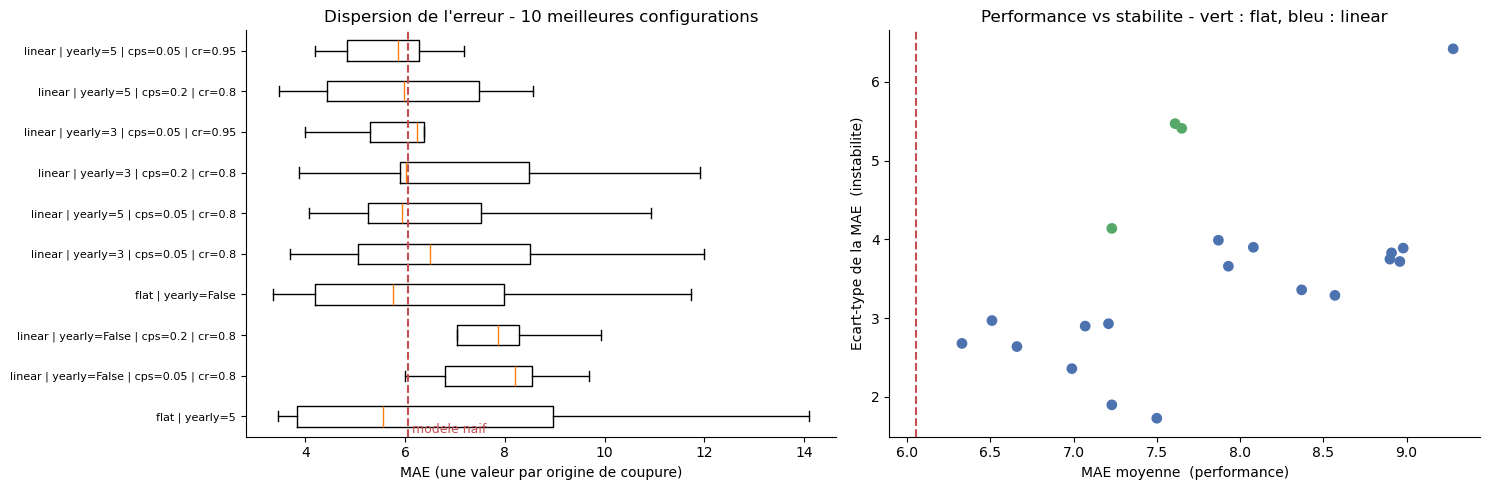

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panneau 1 : dispersion des erreurs par configuration (les 10 meilleures)
top = resume.head(10).index[::-1]
donnees = [detail.loc[detail.config == c, "MAE"].values for c in top]
axes[0].boxplot(donnees, vert=False, showfliers=False)
axes[0].set_yticks(range(1, len(top) + 1))
axes[0].set_yticklabels(top, fontsize=8)
axes[0].axvline(ref_naive_s.mean(), color="#C44E52", ls="--", lw=1.5)
axes[0].set_xlabel("MAE (une valeur par origine de coupure)")
axes[0].set_title("Dispersion de l'erreur - 10 meilleures configurations")
axes[0].text(ref_naive_s.mean(), 0.6, " modele naif", color="#C44E52", fontsize=9)

# Panneau 2 : performance vs stabilite
axes[1].scatter(resume.MAE_moy, resume.MAE_ecart_type, s=45,
                c=["#55A868" if g == "flat" else "#4C72B0"
                   for g in [("flat" if c.startswith("flat") else "linear") for c in resume.index]])
axes[1].axvline(ref_naive_s.mean(), color="#C44E52", ls="--", lw=1.5)
axes[1].set_xlabel("MAE moyenne  (performance)")
axes[1].set_ylabel("Ecart-type de la MAE  (instabilite)")
axes[1].set_title("Performance vs stabilite - vert : flat, bleu : linear")

plt.tight_layout()
plt.show()

**Comment lire ces deux panneaux.**

- **À gauche**, chaque boîte agrège les erreurs d'une configuration sur toutes les origines. Une boîte **étroite** signale une configuration fiable ; une boîte étalée signale une configuration dont la performance dépend de la période — donc imprévisible sur la suivante. Le trait rouge est le modèle naïf.
- **À droite**, le meilleur endroit est le **coin inférieur gauche** : erreur faible *et* stable. Une configuration très à gauche mais très haut est un piège — c'est exactement ce qu'une sélection sur fenêtre unique aurait retenu.
- Le code couleur sépare `flat` de `linear`. Si les points verts se regroupent en bas à gauche, la conclusion est directe : **sur cette série, l'extrapolation de tendance nuit plus qu'elle n'aide.**

### Règle de sélection

La MAE moyenne seule ne suffit pas — le modèle par défaut l'a montré, avec une erreur en apparence acceptable mais des intervalles de confiance ruinés. Deux conditions sont donc imposées avant tout classement :

1. **Couverture moyenne ≥ 80 %** (pour un intervalle annoncé à 95 %). En dessous, les intervalles donnent une fausse assurance et ne sont pas présentables à un comité.
2. **Départage par la stabilité** : à performance équivalente (moins de 2 % d'écart de MAE moyenne), la configuration au plus faible écart-type l'emporte.

Ce n'est qu'ensuite que la MAE moyenne classe les survivantes.

In [26]:
SEUIL_COUVERTURE = 80
MARGE = 0.02   # ecart de MAE en deca duquel deux configurations sont jugees equivalentes

eligibles = resume[resume.couverture_moy >= SEUIL_COUVERTURE]
print(f"Configurations eligibles (couverture >= {SEUIL_COUVERTURE} %) : "
      f"{len(eligibles)} / {len(resume)}")

if len(eligibles) == 0:
    print("\nAUCUNE configuration ne tient le critere de couverture.")
    print("=> Les intervalles de Prophet ne sont pas fiables sur cette serie, "
          "quelle que soit la configuration. A signaler explicitement au comite.")
    eligibles = resume

seuil = eligibles.MAE_moy.min() * (1 + MARGE)
finalistes = eligibles[eligibles.MAE_moy <= seuil].sort_values("MAE_ecart_type")
print(f"\nFinalistes a moins de {MARGE:.0%} de la meilleure MAE : {len(finalistes)}")
finalistes

Configurations eligibles (couverture >= 80 %) : 3 / 21

Finalistes a moins de 2% de la meilleure MAE : 1


,MAE_moy,MAE_ecart_type,MAE_pire,MAPE_moy,biais_moy,couverture_moy,taux_victoire
config,,,,,,,
flat | yearly=False,7.23,4.14,15.85,9.89,-4.28,95.56,56.0


In [27]:
nom_retenu = finalistes.index[0]
meilleure = {k: v for k, v in
             detail[detail.config == nom_retenu].iloc[0][
                 ["growth", "yearly_seasonality", "changepoint_prior_scale",
                  "changepoint_range"]].dropna().items()}

ys = meilleure["yearly_seasonality"]
meilleure["yearly_seasonality"] = bool(ys) if isinstance(ys, (bool, np.bool_)) else int(ys)
for k in ["changepoint_prior_scale", "changepoint_range"]:
    if k in meilleure:
        meilleure[k] = float(meilleure[k])

print(f"Configuration retenue : {nom_retenu}\n")
for k, v in meilleure.items():
    print(f"   {k:<26} = {v}")
print(f"\n   MAE moyenne en validation croisee : {resume.loc[nom_retenu, 'MAE_moy']:.2f} "
      f"(naif : {ref_naive_s.mean():.2f})")
print(f"   Ecart-type                        : {resume.loc[nom_retenu, 'MAE_ecart_type']:.2f}")
print(f"   Taux de victoire sur le naif      : {resume.loc[nom_retenu, 'taux_victoire']:.0f} %")
print(f"   Couverture moyenne                : {resume.loc[nom_retenu, 'couverture_moy']:.1f} %")

Configuration retenue : flat | yearly=False

   growth                     = flat
   yearly_seasonality         = False

   MAE moyenne en validation croisee : 7.23 (naif : 6.06)
   Ecart-type                        : 4.14
   Taux de victoire sur le naif      : 56 %
   Couverture moyenne                : 95.6 %


## 5.6 Jugement final sur le test

La configuration est maintenant **figée**. Elle est ré-entraînée sur l'ensemble de l'historique antérieur au test, puis évaluée **une seule fois** sur des données qui n'ont joué aucun rôle — ni dans l'entraînement, ni dans la sélection.

In [28]:
m_opt = construire_prophet(**meilleure)
m_opt.fit(df_train_complet)
futur_test = m_opt.make_future_dataframe(periods=TEST_J, freq="D")
prev_opt = m_opt.predict(futur_test)
pred_opt = prev_opt.set_index("ds").reindex(test.index)

res_opt = evaluer(test.values, pred_opt.yhat.values, f"Prophet ({meilleure['growth']})")
couv_opt = np.nanmean((test.values >= pred_opt.yhat_lower.values) &
                      (test.values <= pred_opt.yhat_upper.values)) * 100

bilan = pd.DataFrame([res_naif_test, res_def, res_opt]).set_index("modele").round(2)
bilan["gain_MAE_%"] = ((res_naif_test["MAE"] - bilan["MAE"]) / res_naif_test["MAE"] * 100).round(1)
bilan["|biais|/MAE"] = (bilan.biais.abs() / bilan.MAE).round(2)
bilan

,n,MAE,RMSE,MAPE_%,biais,gain_MAE_%,|biais|/MAE
modele,,,,,,,
Naif saisonnier (7 j),90,4.92,5.78,6.68,-3.77,0.0,0.77
Prophet (defaut),90,18.24,19.49,23.94,18.24,-270.6,1.00
Prophet (flat),90,7.41,8.11,10.11,-6.80,-50.5,0.92


In [29]:
print(f"Couverture de l'intervalle a 95 % : "
      f"defaut {np.nanmean(couverture_def)*100:.1f} % -> retenu {couv_opt:.1f} %")

gain = (res_naif_test["MAE"] - res_opt["MAE"]) / res_naif_test["MAE"] * 100
coherence = "CONFIRME" if (res_opt["MAE"] < res_naif_test["MAE"]) == \
                          (resume.loc[nom_retenu, "MAE_moy"] < ref_naive_s.mean()) else "CONTREDIT"
print(f"\nLe test {coherence} le verdict de la validation croisee.")
print(f"   validation croisee : Prophet {resume.loc[nom_retenu, 'MAE_moy']:.2f} "
      f"vs naif {ref_naive_s.mean():.2f}")
print(f"   test               : Prophet {res_opt['MAE']:.2f} vs naif {res_naif_test['MAE']:.2f}")

Couverture de l'intervalle a 95 % : defaut 6.7 % -> retenu 100.0 %

Le test CONFIRME le verdict de la validation croisee.
   validation croisee : Prophet 7.23 vs naif 6.06
   test               : Prophet 7.41 vs naif 4.92


In [30]:
# --- Commentaire automatique, en langage metier ---------------------------
print(f"Le modele retenu se trompe en moyenne de {res_opt['MAE']:.1f} morceaux par jour "
      f"({res_opt['MAPE_%']:.1f} % de la valeur reelle),")
print(f"contre {res_def['MAE']:.1f} pour la configuration par defaut "
      f"et {res_naif_test['MAE']:.1f} pour le modele naif.\n")

if gain > 10:
    print(f"=> Prophet bat la reference naive de {gain:.0f} % : sa complexite est justifiee.")
elif gain > 0:
    print(f"=> Prophet ne devance la reference naive que de {gain:.0f} %. Le gain est reel mais "
          f"modeste ; il se paie en intervalles de confiance et en composantes interpretables, "
          f"pas en precision brute.")
else:
    print(f"=> Prophet reste en dessous de la reference naive ({gain:.0f} %). A annoncer tel quel : "
          f"sur cette serie, la meilleure prevision est proche du niveau courant, et la "
          f"sophistication n'apporte que ses intervalles et sa decomposition.")

if abs(res_opt["biais"]) / res_opt["MAE"] > 0.6:
    print("\nATTENTION : l'erreur reste majoritairement systematique (biais eleve). "
          "Le modele derive dans une direction constante.")
if couv_opt < 80:
    print(f"ATTENTION : couverture de {couv_opt:.0f} % au lieu de 95 % attendus. "
          "Ne pas presenter ces intervalles comme fiables.")

Le modele retenu se trompe en moyenne de 7.4 morceaux par jour (10.1 % de la valeur reelle),
contre 18.2 pour la configuration par defaut et 4.9 pour le modele naif.

=> Prophet reste en dessous de la reference naive (-51 %). A annoncer tel quel : sur cette serie, la meilleure prevision est proche du niveau courant, et la sophistication n'apporte que ses intervalles et sa decomposition.

ATTENTION : l'erreur reste majoritairement systematique (biais eleve). Le modele derive dans une direction constante.


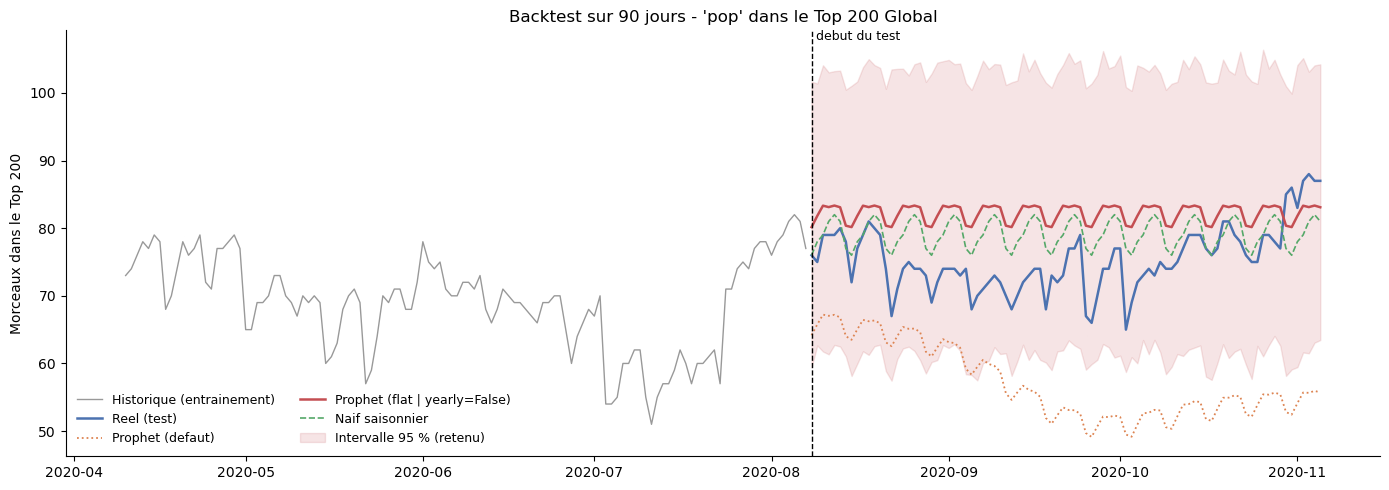

In [31]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train_complet.index[-120:], train_complet.values[-120:], color="#999", lw=1,
        label="Historique (entrainement)")
ax.plot(test.index, test.values, color="#4C72B0", lw=1.8, label="Reel (test)")
ax.plot(test.index, pred_def.yhat, color="#DD8452", lw=1.3, ls=":", label="Prophet (defaut)")
ax.plot(test.index, pred_opt.yhat, color="#C44E52", lw=1.8, label=f"Prophet ({nom_retenu})")
ax.plot(test.index, naif_test, color="#55A868", lw=1.2, ls="--", label="Naif saisonnier")
ax.fill_between(test.index, pred_opt.yhat_lower, pred_opt.yhat_upper,
                color="#C44E52", alpha=0.15, label="Intervalle 95 % (retenu)")
ax.axvline(debut_test, color="k", ls="--", lw=1)
ax.text(debut_test, ax.get_ylim()[1], " debut du test", va="top", fontsize=9)
ax.set_title(f"Backtest sur {TEST_J} jours - '{GENRE}' dans le Top 200 {MARCHE}")
ax.set_ylabel("Morceaux dans le Top 200")
ax.legend(loc="lower left", frameon=False, ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

## 5.7 Composantes du modèle retenu

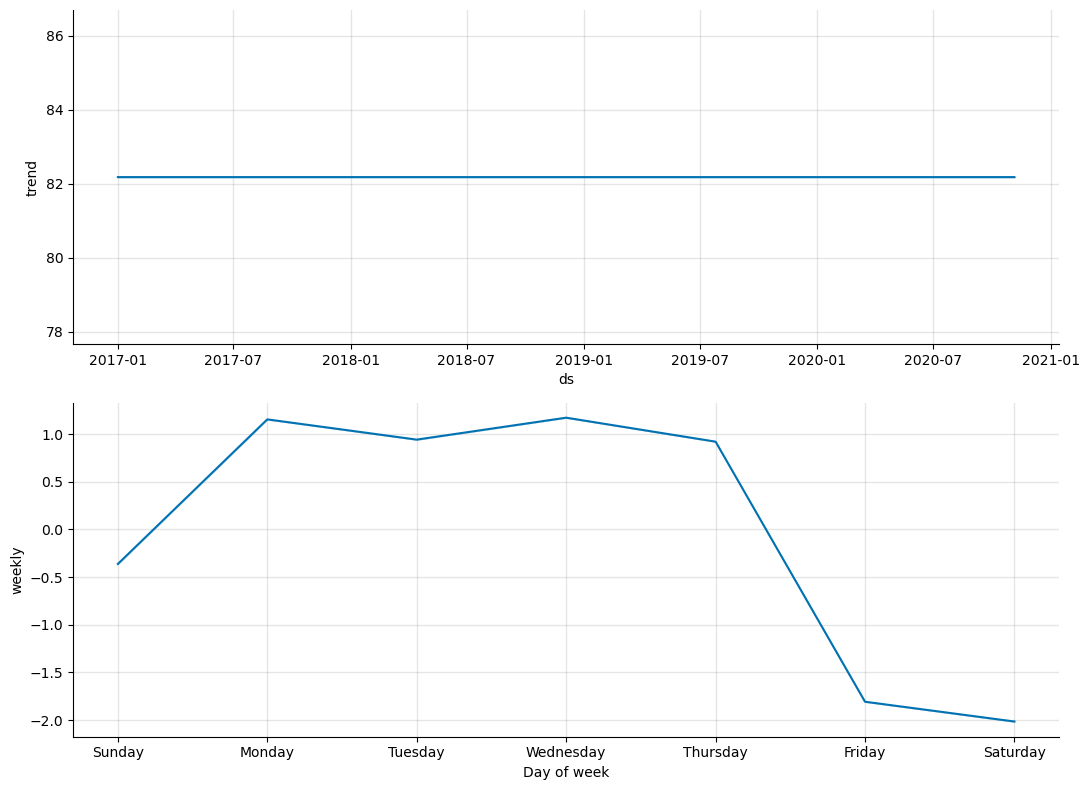

Amplitude 'trend' : defaut   44.9 -> optimise    0.0 morceaux
Amplitude 'weekly' : defaut    3.4 -> optimise    3.2 morceaux


In [32]:
fig = m_opt.plot_components(prev_opt)
fig.set_size_inches(11, 8)
plt.tight_layout()
plt.show()

for comp in ["trend", "weekly", "yearly"]:
    if comp in prev_opt.columns:
        amp_def = (prev_def[comp].max() - prev_def[comp].min()) if comp in prev_def else np.nan
        amp_opt = prev_opt[comp].max() - prev_opt[comp].min()
        print(f"Amplitude '{comp}' : defaut {amp_def:>6.1f} -> optimise {amp_opt:>6.1f} morceaux")

**Ce qu'on attend de la comparaison des amplitudes.**

- La composante **annuelle** doit être nettement réduite, voire absente si `yearly_seasonality=False` a été retenu. C'est le cœur du correctif : on a retiré au modèle la liberté d'inventer un motif que 4 cycles ne peuvent pas établir.
- La composante **hebdomadaire** doit rester stable et conserver son **creux vendredi-samedi**. Ce motif-là s'appuie sur près de 200 répétitions : il est solide, et le tuning ne doit pas l'avoir effacé. S'il a disparu, c'est que la régularisation est trop forte.
- La **tendance** doit épouser plus fidèlement la dynamique de 2020 si `changepoint_range=0.95` a été retenu.

**Le renoncement à assumer.** Supprimer la saisonnalité annuelle n'affirme pas qu'il n'y a pas de saisonnalité annuelle dans le streaming musical. Cela dit qu'**avec 4 ans d'historique, on ne peut pas l'estimer de façon fiable**, et qu'un motif mal estimé nuit plus qu'il n'aide. Distinction essentielle à formuler devant le comité.

## 5.8 Prévision finale à 6 mois

Le backtest a servi à **évaluer**. Il serait absurde de livrer une prévision issue d'un modèle privé des 90 derniers jours d'historique — les plus informatifs. On ré-entraîne donc sur **l'intégralité des données connues**, avec la configuration retenue, inchangée.

In [33]:
df_complet = au_format_prophet(serie)

modele_final = construire_prophet(**meilleure)   # configuration retenue, inchangee
modele_final.fit(df_complet)

futur = modele_final.make_future_dataframe(periods=HORIZON, freq="D")
prevision = modele_final.predict(futur)
horizon_df = prevision[prevision.ds > serie.index.max()]

print(f"Prevision : {horizon_df.ds.min():%Y-%m-%d} -> {horizon_df.ds.max():%Y-%m-%d} "
      f"({len(horizon_df)} jours)")

Prevision : 2020-11-06 -> 2021-05-04 (180 jours)


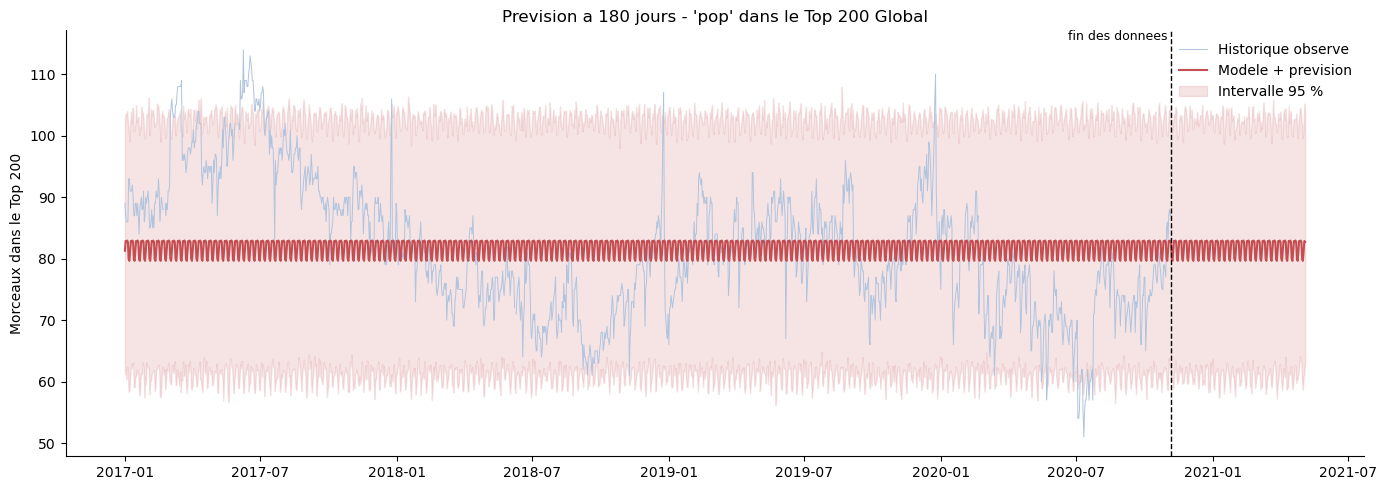

In [34]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(serie.index, serie.values, color="#B0C4DE", lw=0.7, label="Historique observe")
ax.plot(prevision.ds, prevision.yhat, color="#C44E52", lw=1.5, label="Modele + prevision")
ax.fill_between(prevision.ds, prevision.yhat_lower, prevision.yhat_upper,
                color="#C44E52", alpha=0.15, label="Intervalle 95 %")
ax.axvline(serie.index.max(), color="k", ls="--", lw=1)
ax.text(serie.index.max(), ax.get_ylim()[1], " fin des donnees ", va="top", ha="right", fontsize=9)
ax.set_title(f"Prevision a {HORIZON} jours - '{GENRE}' dans le Top 200 {MARCHE}")
ax.set_ylabel("Morceaux dans le Top 200")
ax.legend(loc="upper right", frameon=False)
plt.tight_layout()
plt.show()

In [35]:
synthese = (horizon_df.set_index("ds")[["yhat", "yhat_lower", "yhat_upper"]]
                      .resample("MS").mean().round(1))
synthese.columns = ["prevision", "borne_basse", "borne_haute"]
synthese["largeur_IC"] = (synthese.borne_haute - synthese.borne_basse).round(1)
synthese.index = synthese.index.strftime("%Y-%m")

niveau_actuel = serie.tail(30).mean()
print(f"Niveau observe sur les 30 derniers jours : {niveau_actuel:.1f} morceaux/jour")
print(f"Prevision moyenne sur l'horizon          : {horizon_df.yhat.mean():.1f} morceaux/jour")
print(f"Evolution attendue                       : "
      f"{(horizon_df.yhat.mean() - niveau_actuel) / niveau_actuel * 100:+.1f} %\n")
print(f"Largeur de l'intervalle : {synthese.largeur_IC.iloc[0]:.0f} morceaux au 1er mois "
      f"-> {synthese.largeur_IC.iloc[-1]:.0f} au 6e (l'incertitude croit avec l'horizon)\n")

# --- Controle de vraisemblance de la prevision ------------------------------
# Une prevision qui sort de l'enveloppe historique observee doit etre justifiee
# par autre chose qu'une extrapolation de tendance.
hist_min, hist_max = serie.min(), serie.max()
prev_min, prev_max = horizon_df.yhat.min(), horizon_df.yhat.max()
print(f"Enveloppe historique observee : {hist_min:.0f} - {hist_max:.0f} morceaux/jour")
print(f"Enveloppe de la prevision     : {prev_min:.0f} - {prev_max:.0f} morceaux/jour")
if prev_max > hist_max or prev_min < hist_min:
    print("\nALERTE : la prevision sort de l'enveloppe jamais observee en 4 ans.")
    print("   Sur une serie sans rupture structurelle connue, c'est le signe d'une")
    print("   extrapolation de tendance divergente. Ne pas communiquer ces chiffres.")
else:
    print("\nLa prevision reste dans l'enveloppe historique : pas d'extrapolation aberrante.")

synthese

Niveau observe sur les 30 derniers jours : 79.2 morceaux/jour
Prevision moyenne sur l'horizon          : 81.7 morceaux/jour
Evolution attendue                       : +3.2 %

Largeur de l'intervalle : 41 morceaux au 1er mois -> 42 au 6e (l'incertitude croit avec l'horizon)

Enveloppe historique observee : 51 - 114 morceaux/jour
Enveloppe de la prevision     : 80 - 83 morceaux/jour

La prevision reste dans l'enveloppe historique : pas d'extrapolation aberrante.


,prevision,borne_basse,borne_haute,largeur_IC
ds,,,,
2020-11,81.6,61.0,102.4,41.4
2020-12,81.8,61.1,102.8,41.7
2021-01,81.6,60.6,102.5,41.9
2021-02,81.7,61.0,102.2,41.2
2021-03,81.8,60.8,102.6,41.8
2021-04,81.7,61.0,102.4,41.4
2021-05,81.6,61.0,102.7,41.7


## 5.9 Ce que cette prévision peut dire, et ce qu'elle ne peut pas dire

Camille demande explicitement d'être clair sur les deux.

**Ce qu'elle peut dire**

- La **direction** du mouvement de fond sur 6 mois, et son ordre de grandeur.
- Le **rythme hebdomadaire** attendu, exploitable pour caler un jour de sortie.
- Une **fourchette** plutôt qu'un chiffre unique : c'est l'intervalle qui doit être communiqué aux labels, jamais la valeur centrale seule.

**Ce qu'elle ne peut pas dire**

- **Elle repose sur l'hypothèse de continuité des motifs passés.** Prophet prolonge ce qu'il a observé. Un changement de l'algorithme de classement Spotify, l'irruption d'un genre ou une sortie exceptionnelle ne figurent dans aucune donnée d'entraînement.
- **Sa fiabilité décroît avec l'horizon** : l'élargissement de l'intervalle entre le 1er et le 6e mois le chiffre explicitement.
- **Elle ne dit rien des causes.** Elle constate un mouvement, sans indiquer au bénéfice de quel genre. Le paramètre `GENRE` permet de le vérifier sur `rap`, `latin`, `hip hop`.
- **La période d'entraînement inclut 2020**, année atypique pour l'industrie musicale : le modèle a partiellement appris un régime exceptionnel.
- **Elle prévoit une présence dans un classement, pas des écoutes ni des revenus.** Le Top 200 est à taille fixe : perdre des places signifie céder du terrain en relatif, pas nécessairement reculer en absolu.
- **La marge d'erreur du backtest est un plancher, pas un plafond.** Elle a été mesurée sur 90 jours ; à 180 jours, l'erreur réelle sera supérieure.

---
# Étape 6 — Cadence de sortie et synthèse

## 6.1 Construction de la série mensuelle des sorties

Second angle : non plus « quelle place le genre occupe dans les charts », mais « à quel rythme il produit ». La maille est ici **mensuelle**, la source étant les dates de sortie officielles.

In [36]:
serie_m = (sorties.query("genre == @GENRE")
                   .set_index("mois")["n_sorties"]
                   .sort_index())

grille_m = pd.date_range(serie_m.index.min(), serie_m.index.max(), freq="MS")
serie_m = serie_m.reindex(grille_m)
serie_m.index.name = "mois"

print(f"Periode : {serie_m.index.min():%Y-%m} -> {serie_m.index.max():%Y-%m}")
print(f"Points  : {len(serie_m)} mois (dont {serie_m.isna().sum()} manquants)")
print(serie_m.describe()[["mean", "std", "min", "max"]].round(1).to_string())

Periode : 2017-01 -> 2020-10
Points  : 46 mois (dont 0 manquants)
mean    314.4
std      80.0
min     187.0
max     538.0


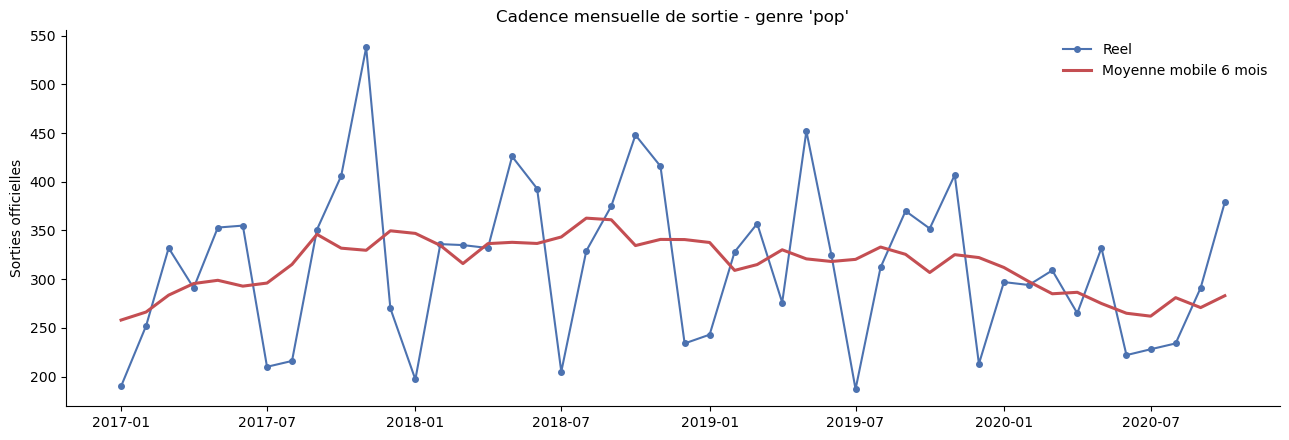

Moyenne par annee :
mois
2017    313.7
2018    335.5
2019    318.5
2020    285.1


In [37]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(serie_m.index, serie_m.values, marker="o", ms=4, lw=1.5, color="#4C72B0", label="Reel")
ax.plot(serie_m.index, serie_m.rolling(6, center=True, min_periods=3).mean(),
        lw=2.2, color="#C44E52", label="Moyenne mobile 6 mois")
ax.set_title(f"Cadence mensuelle de sortie - genre '{GENRE}'")
ax.set_ylabel("Sorties officielles")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print("Moyenne par annee :")
print(serie_m.groupby(serie_m.index.year).mean().round(1).to_string())

> **Limite structurelle du support.** 46 points mensuels, soit moins de 4 cycles annuels complets. Exactement le problème qui a fait échouer le modèle par défaut sur la série quotidienne — **en pire**, puisqu'on dispose ici de 46 observations au lieu de 1 400. La saisonnalité annuelle sera donc bridée dès le départ.

## 6.2 Prévision mensuelle et évaluation sur 6 mois

Avec 46 points, un découpage en trois blocs ne serait pas tenable : la période d'entraînement deviendrait trop courte. On se limite donc à **entraînement / test**, avec une grille réduite à 6 configurations — et on assume que ce choix se fait au vu du test. **Ce n'est pas rigoureux, et cela doit être dit** : les chiffres d'erreur de cette section sont optimistes.

In [38]:
TEST_M = 6
coupure_m = serie_m.index[-TEST_M]

train_m = serie_m[serie_m.index <  coupure_m]
test_m  = serie_m[serie_m.index >= coupure_m]

print(f"Entrainement : {train_m.index.min():%Y-%m} -> {train_m.index.max():%Y-%m} ({len(train_m)} mois)")
print(f"Test         : {test_m.index.min():%Y-%m} -> {test_m.index.max():%Y-%m} ({len(test_m)} mois)")

naif_m = np.repeat(train_m.dropna().iloc[-1], len(test_m))
res_naif_m = evaluer(test_m.values, naif_m, "Naif (dernier mois)")
print(f"\nReference naive - MAE {res_naif_m['MAE']:.1f} | RMSE {res_naif_m['RMSE']:.1f} "
      f"| MAPE {res_naif_m['MAPE_%']:.1f} %")

Entrainement : 2017-01 -> 2020-04 (40 mois)
Test         : 2020-05 -> 2020-10 (6 mois)

Reference naive - MAE 53.0 | RMSE 61.0 | MAPE 18.0 %


In [39]:
df_train_m = au_format_prophet(train_m)

configs_m = [
    {"yearly_seasonality": False, "changepoint_prior_scale": 0.05},
    {"yearly_seasonality": False, "changepoint_prior_scale": 0.2},
    {"yearly_seasonality": 2,     "changepoint_prior_scale": 0.05},
    {"yearly_seasonality": 2,     "changepoint_prior_scale": 0.2},
    {"yearly_seasonality": 5,     "changepoint_prior_scale": 0.05},
    {"yearly_seasonality": 10,    "changepoint_prior_scale": 0.05},
]

lignes = []
for cfg in configs_m:
    m = Prophet(weekly_seasonality=False,   # serie mensuelle : aucun motif hebdomadaire observable
                daily_seasonality=False,
                seasonality_mode="additive",
                interval_width=0.95,
                **cfg)
    m.fit(df_train_m)
    futur_m = m.make_future_dataframe(periods=TEST_M, freq="MS")
    p = m.predict(futur_m).set_index("ds").reindex(test_m.index)
    nom = f"yearly={cfg['yearly_seasonality']}, cps={cfg['changepoint_prior_scale']}"
    lignes.append({**evaluer(test_m.values, p.yhat.values, nom), "pred": p})

res_m = pd.DataFrame([{k: v for k, v in l.items() if k != "pred"} for l in lignes])
res_m = pd.concat([pd.DataFrame([res_naif_m]), res_m]).set_index("modele").round(2)
res_m

,n,MAE,RMSE,MAPE_%,biais
modele,,,,,
Naif (dernier mois),6,53.00,61.02,18.01,16.00
"yearly=False, cps=0.05",6,64.09,72.97,25.84,-43.28
"yearly=False, cps=0.2",6,63.09,71.35,25.30,-40.26
"yearly=2, cps=0.05",6,45.99,49.91,17.60,-45.99
"yearly=2, cps=0.2",6,29.08,34.88,11.35,-29.08
"yearly=5, cps=0.05",6,71.02,79.83,27.49,-59.22
"yearly=10, cps=0.05",6,47.89,79.45,20.81,-15.55


Configuration mensuelle retenue : yearly=2, cps=0.2


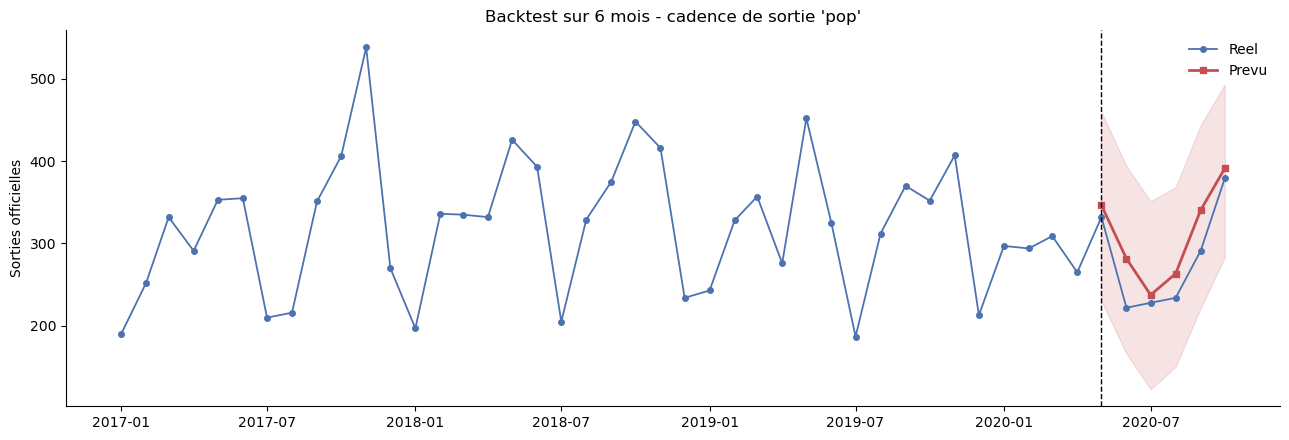

In [40]:
meilleur_idx = int(np.argmin([l["MAE"] for l in lignes]))
pred_m = lignes[meilleur_idx]["pred"]
print(f"Configuration mensuelle retenue : {lignes[meilleur_idx]['modele']}")

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(serie_m.index, serie_m.values, marker="o", ms=4, lw=1.3, color="#4C72B0", label="Reel")
ax.plot(pred_m.index, pred_m.yhat, marker="s", ms=5, lw=2, color="#C44E52", label="Prevu")
ax.fill_between(pred_m.index, pred_m.yhat_lower, pred_m.yhat_upper, color="#C44E52", alpha=0.15)
ax.axvline(coupure_m, color="k", ls="--", lw=1)
ax.set_title(f"Backtest sur {TEST_M} mois - cadence de sortie '{GENRE}'")
ax.set_ylabel("Sorties officielles")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 6.3 Fragilité conceptuelle de cette seconde prévision

**Le point à porter en slide.** Cette prévision est structurellement moins solide que la première, pour une raison qui ne tient pas au modèle mais à la construction de la donnée.

**La collecte s'arrête fin 2020.** Or un morceau n'entre dans le fichier des sorties que s'il a atteint les classements. Les titres sortis dans les derniers mois **n'ont pas encore eu le temps d'y parvenir** : ils manquent au décompte. La série est donc **artificiellement rabotée sur sa fin**, et l'effet s'accentue à mesure qu'on approche de la date d'arrêt.

**Trois conséquences directes :**

1. La période de test est précisément la plus tronquée. Le modèle est jugé sur des valeurs réelles elles-mêmes sous-estimées.
2. Une baisse apparente de la cadence en fin de série est **au moins en partie un artefact de collecte**, pas un ralentissement de production.
3. Toute prévision prolongeant cette pente hérite du biais et l'aggrave.

**Deux limites supplémentaires, propres à cette section :**

- **46 points d'entraînement**, contre 1 400 pour la série quotidienne. Le rapport observations/paramètres est défavorable quelle que soit la configuration.
- **La sélection s'est faite sur le test**, faute de longueur suffisante pour un bloc de validation. Les chiffres d'erreur affichés sont donc optimistes.

**Ce qu'on en fait.** Cette série ne se prête pas à un chiffrage communiqué aux labels. Elle reste utile en lecture qualitative — ordre de grandeur, comparaison entre genres sur les périodes non affectées. Un correctif rigoureux supposerait de connaître le délai moyen entre sortie et entrée en classement, puis de tronquer la série de cette durée. Cette information n'est pas dans les données fournies.

**Nuance sur la comparabilité.** Les deux fichiers ne partagent pas la même nomenclature de genre (`genre` côté classements, `Genre_new` côté sorties). Rien ne garantit qu'un titre étiqueté `pop` dans l'un le soit dans l'autre. Les deux séries s'éclairent mutuellement mais ne sont pas rigoureusement superposables.

---
## 6.4 Synthèse à destination de Camille

### Ce que l'analyse établit

1. **La donnée est saine, une fois deux pièges écartés.** Sur 1 405 jours calendaires, 4 dates manquent au fichier (trous de collecte confirmés sur les 35 marchés simultanément) et 1 date est corrompue (2018-06-09 : 200 lignes, un seul morceau distinct). **Aucun vrai zéro** : la Pop n'a jamais quitté le Top 200 Global. Les 5 discontinuités sont traitées en `NaN`, jamais en 0.

2. **La Pop recule dans les classements, sans effondrement.** De ≈ 94 morceaux/jour en 2017 à ≈ 74 en 2020, avec un rebond en 2019 qui interdit toute lecture linéaire. Le Top 200 étant à taille fixe, ce recul se lit comme une **perte de part**, pas comme une baisse d'activité absolue.

3. **Le rythme hebdomadaire est réel mais secondaire** : creux vendredi-samedi, écart de 3,3 morceaux (4 % de la moyenne). Contre-intuitif au premier abord, cohérent une fois posé que l'afflux de nouveautés du vendredi, tous genres confondus, évince mécaniquement le genre dominant d'un classement à taille fixe.

4. **La configuration par défaut de Prophet échoue sur cette série, et le tuning était nécessaire.** Le modèle initial fabriquait une saisonnalité annuelle à partir de moins de 4 cycles et se trompait systématiquement dans le même sens. Le correctif a consisté à brider cette composante et à laisser la tendance s'ajuster aux données récentes.

5. **La prévision de cadence de sortie reste une indication qualitative**, du fait de la troncature de fin de collecte et du faible nombre de points.

### Recommandations opérationnelles

| Recommandation | Fondement |
|---|---|
| Communiquer une fourchette, jamais un chiffre unique | L'incertitude s'élargit avec l'horizon ; un chiffre isolé donne une fausse précision |
| Éviter de caler une sortie Pop majeure un vendredi | Concurrence maximale des nouveautés ce jour-là dans un classement à taille fixe |
| Réexécuter le notebook sur `rap`, `latin`, `hip hop` | Le paramètre `GENRE` suffit ; confirmerait au bénéfice de quel genre la Pop cède du terrain |
| Réactualiser le modèle chaque trimestre, tuning compris | L'hypothèse de continuité des motifs se dégrade avec le temps, et la configuration optimale avec elle |
| Ne pas chiffrer la cadence de sortie auprès des labels | Biais de troncature non corrigeable avec les données disponibles |

### Les deux points de méthode à retenir

**Séparation stricte des rôles.** Trois blocs chronologiques disjoints : l'entraînement ajuste, la validation choisit, le test juge — une seule fois. Sans cette séparation, la performance annoncée mesurerait la capacité du modèle à coller à des données qu'il a servi à sélectionner, c'est-à-dire rien.

**Un modèle sophistiqué n'est pas supposé meilleur.** Toute configuration a été comparée à un modèle naïf reproduisant la dernière semaine observée. C'est ce seuil qui décide si la complexité se justifie — et il n'est pas acquis d'avance.